In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF
from functions import AlgCoM
from functions import AlgYe
from functions import AlgProxPen
from functions import linear

In [2]:
#X,Y must be a box
Y=[(0,1)]
n=3
X=[]
def fcp(x):
    return x[-1]

def fs(x):
    return np.sin(np.pi*x)
    
def gcp(x,y):
    return cp.abs(cp.sum([x[i]*y**i for i in range(n)])-fs(y))-x[-1]

def f(x):
    return x[-1]

def df(x):
    v=np.zeros(n+1)
    v[-1]=1
    return v


def g(x,y):
    return np.abs(np.sum([x[i]*y**i for i in range(n)])-fs(y))-x[-1]

def dg(x,y):
    v=np.zeros(n+1)
    v[-1]=-1
    for i in range(n):
        if np.sum([x[i]*y**i for i in range(n)])-fs(y)>0:
            v[i]=y**i
        else:
            v[i]=-y**i
    return v

def poly(d,coeff,x):
    return np.sum([coeff[i]*x**i for i in range(d)])

In [3]:
y0=np.array([[0.5]])
x0=np.zeros(n+1)
res1=AlgProxPen(x0,y0,fcp,gcp,g,X,Y,f=fcp,df=df,rho=1,tol=10**-3,gamma=100)

-0.001715549046349116
1.2110208214409998e-06
1.095302463574616e-06
0.027591190158310044
0.027752236158956927
0.027991363493593612
Time 0.7438795566558838
Time upper problem 0.35178041458129883
Time lower problem 0.38918232917785645
Feasibility 3.732945597677631e-05
Final rho 2
Rho increases 1
Optimal value 0.027991363493593612
Value function call 8


In [4]:
res3=AlgMePa(x0,y0,fcp,gcp,g,X,Y)
print(res3[0])

Time 0.7097539901733398
Time upper problem 0.2919192314147949
Time lower problem 0.4171943664550781
Feasibility -7.852033922482043e-06
Optimal value 0.028008386971323747
Optimality cuts 3
Feasibility cuts 6
Value function calls 9
[-0.02800844  4.00001349 -4.00001113  0.02800553]


In [ ]:
res2=AlgYe(x0,y0,fcp,gcp,fcp,g,df,dg,X,Y)

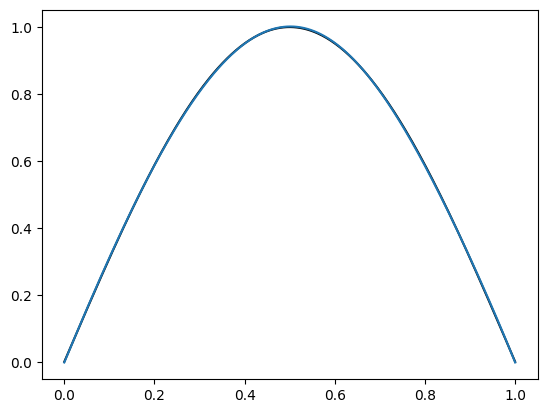

In [4]:
N = 400
x = np.linspace(Y[0][0], Y[0][1], N)


fig, ax = plt.subplots()
ax.plot(x, fs(x), "k")
poly1=[poly(n,res1[0],xi) for xi in x]
ax.plot(x, poly1)

In [11]:
import numpy as np

def f(x):
    r1 = x[0] - 2*x[1] + 5*x[1]**2 - x[1]**3 - 13
    r2 = x[0] - 14*x[1] + x[1]**2 + x[1]**3 - 29
    return r1**2 + r2**2

def grad_f(x):
    r1 = x[0] - 2*x[1] + 5*x[1]**2 - x[1]**3 - 13
    r2 = x[0] - 14*x[1] + x[1]**2 + x[1]**3 - 29
    df_dx0 = 2*(r1 + r2)
    df_dx1 = 2*(r1*(-2 + 10*x[1] - 3*x[1]**2) + r2*(-14 + 2*x[1] + 3*x[1]**2))
    return np.array([df_dx0, df_dx1])

def gcp(x,y):
    return x[0]**2+2*x[1]*y**2+cp.exp(x[0]+x[1])-np.exp(y)

def g(x,y):
    return x[0]**2+2*x[1]*y**2+np.exp(x[0]+x[1])-np.exp(y)

def dg(x,y):
    d1=2*x[0]+np.exp(x[0]+x[1])
    d2=2*y**2+np.exp(x[0]+x[1])
    return np.array([d1,d2])

In [9]:
Y=[(0,1)]
n=2
A=np.zeros((2*n,n))
b=2*np.ones((2*n))
for i in range(n):
    A[i][i]=-1
    A[n+i][i]=1
        
#X=[(linear,[A,b])]
X=[]
y0=np.array([[0.5]])
x0=np.array([1,2])
res1=AlgProxPen(x0,y0,f,gcp,g,X,Y,f=f,df=grad_f,rho=1,tol=10**-3,gamma=0.001)

1879.6765153961692
1630.0838790579858
891.0401649879907
56.24898950341249
204.06945751811546
90.03361280550035
354.47000528294706
332.272789751748
935.3553353415829
1946.6491299437794
1682.548913851043
1021.5048884226404
311.90224253600127
112.39141175134105
111.11894893738679
110.34135247424169
110.0075261660055
109.78787942342124
109.63125684353535
109.49607070632811
109.37083292802869
109.24949992983247
109.12997735430821
109.011329078476
108.89319990167769
108.77544110749344
108.65799390929772
108.54083409796058
108.423951585992
108.30734193191213
108.19100288828066
108.07493313397752


KeyboardInterrupt: 

In [13]:
res2=AlgYe(x0,y0,f,gcp,f,g,grad_f,dg,X,Y)

C:\Users\ricca\Desktop\serrrrpenti\optimization\SIP\TEST\new_version\functions.py:662: RuntimeWarning: overflow encountered in exp
  return np.exp(rho*g(x,y))
C:\Users\ricca\AppData\Local\Temp\ipykernel_33076\3331433619.py:19: RuntimeWarning: overflow encountered in exp
  return x[0]**2+2*x[1]*y**2+np.exp(x[0]+x[1])-np.exp(y)


118.05327719427105
1.3813619799954069
117.57585017995095
0.21473109802995863
108.42914292978467
0.38755878840117425
112.3704676526167
0.12422715213155525
108.90298398297264
0.042803132427217325
111.32996773450253
0.09230601986795843
107.90668975494968
0.03046363088117932
108.69286492806391
0.011696340641527298
107.58941142024432
0.022739222078019643
108.44451680344542
0.009298283435482457
108.13289056492064
0.0034153326330281283
108.28850848929996
0.005448594927145287
108.0540443206334
0.0023250332565320653
108.16871506019007
0.0020970996460057344
108.00808732542029
0.0015898347635980954
108.05426485050863
0.000846141396722364
107.96934498148343
0.0008500962351056433
107.95939719319776
0.00014684029858347145
107.92601480582076
0.0003512611246087356
107.89781616982006
0.0003078495396034878
107.86641364267388
0.00034251044838113726
107.83419192706273
0.00035551354189116807
107.80040508608951
0.00037571813091510816
107.76521414653618
0.000394815372463016
107.72851743637561
0.0004152912850

C:\Users\ricca\Desktop\serrrrpenti\optimization\SIP\TEST\new_version\functions.py:667: RuntimeWarning: divide by zero encountered in log
  return np.log(I[0])/rho
C:\Users\ricca\Desktop\serrrrpenti\optimization\SIP\TEST\new_version\functions.py:676: RuntimeWarning: invalid value encountered in scalar add
  return f(x)+lambd/2*(np.sqrt(gammar**2+1/rho)+gammar)
C:\Users\ricca\Desktop\serrrrpenti\optimization\SIP\TEST\new_version\functions.py:680: RuntimeWarning: invalid value encountered in scalar divide
  return df(x)+lambd/2*(gammar/np.sqrt(gammar**2+1/rho)+1)*dgammar


TypeError: 'NoneType' object is not subscriptable